# 02 · EDA: What does our real heat data look like?
**Who this is for:** beginners. Every step says what it does and why.
**Needs:** `data/silver/climate_daily.parquet`, `data/silver/districts.parquet`, `data/gold/heat_features.parquet`
(run `bhunetra ingest history`, `bhunetra build`, `bhunetra build-gold` first).
All numbers below come from real ERA5-based data downloaded from Open-Meteo. Nothing here is simulated.

In [1]:
import os, pandas as pd, numpy as np, matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
D = os.environ.get("BHUNETRA_DATA_DIR", "data")
clim = pd.read_parquet(f"{D}/silver/climate_daily.parquet")
dist = pd.read_parquet(f"{D}/silver/districts.parquet")
gold = pd.read_parquet(f"{D}/gold/heat_features.parquet")
print(f"{len(clim):,} district-days | {clim.district_id.nunique()} districts | {clim.date.min().date()} to {clim.date.max().date()}")
print("missing values:", int(clim.isna().sum().sum()), "| duplicate (district, date):", int(clim.duplicated(['district_id','date']).sum()))

109,620 district-days | 60 districts | 2020-01-01 to 2024-12-31
missing values: 0 | duplicate (district, date): 0


## 1. Data tour
One row = one district on one day. `temperature_2m_max` (Tmax) is the hottest hour of that day.
**Limit to remember:** ERA5 is a ~25 km grid model, not a thermometer. It tends to smooth out the hottest peaks.

In [2]:
clim.describe().loc[['min','mean','max'], ['temperature_2m_max','temperature_2m_min','apparent_temperature_max','precipitation_sum','wind_speed_10m_max']].round(1)

,temperature_2m_max,temperature_2m_min,apparent_temperature_max,precipitation_sum,wind_speed_10m_max
min,-18.0,-30.6,-22.2,0.0,1.9
mean,28.9,18.9,31.1,4.3,14.1
max,48.9,34.8,49.9,349.6,80.7


## 2. Seasons
Heat is a summer story. The chart shows the average and the hottest Tmax for each month, across all 60 districts.

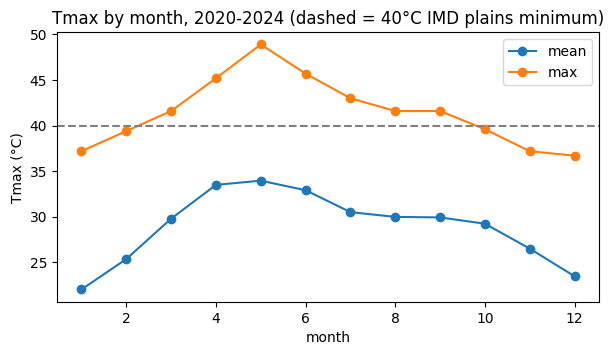

In [3]:
m = clim.assign(month=clim.date.dt.month).groupby("month").temperature_2m_max.agg(["mean", "max"])
ax = m.plot(marker="o", figsize=(7, 3.5)); ax.set_ylabel("Tmax (°C)"); ax.axhline(40, ls="--", c="grey"); ax.set_title("Tmax by month, 2020-2024 (dashed = 40°C IMD plains minimum)")
plt.show()

## 3. Our heat label (IMD-style rule)
A day counts as a **heat event** if Tmax is at least 40°C and (it is at least 4.5°C above that district's normal, or at least 45°C).
The *normal* comes from **2020-2022 only**, so the 2023-24 test years never influence it (see `docs/targets.md`).
This is a simplified version of IMD's rule (grid not stations, single days, all districts = plains).

heat events (day t) by year:
      events  rate_pct
year                  
2020      53      0.25
2021      25      0.11
2022     325      1.48
2023     253      1.16
2024     615      2.82


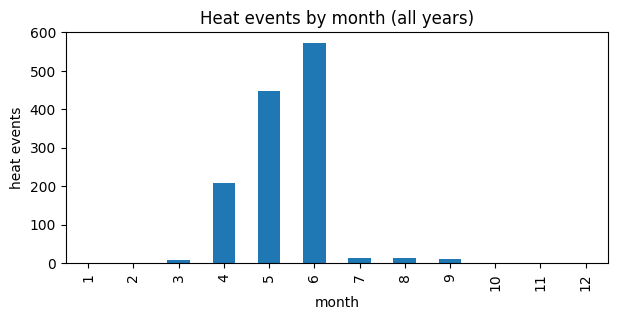

April-June share of all events: 96.5%


In [4]:
lab = gold.assign(year=gold.date.dt.year, month=gold.date.dt.month)
print("heat events (day t) by year:"); print(lab.groupby("year").heat_today.agg(events="sum", rate_pct=lambda s: round(100*s.mean(), 2)).to_string())
ev = lab.groupby("month").heat_today.sum()
ax = ev.plot.bar(figsize=(7, 3)); ax.set_ylabel("heat events"); ax.set_title("Heat events by month (all years)"); plt.show()
print(f"April-June share of all events: {100*ev.loc[4:6].sum()/ev.sum():.1f}%")

## 4. Where? (state view)
Only 60 sampled districts (about 1 to 6 per state), so state totals depend on how many districts we sampled. Do **not** read this as a ranking of states.

In [5]:
e = gold[gold.heat_today == 1].merge(dist[["district_id", "state"]], on="district_id")
per = e.groupby("state").size().rename("events").to_frame().join(dist[dist.in_study_sample].groupby("state").size().rename("districts_sampled"))
per["events_per_district"] = (per.events / per.districts_sampled).round(1)
per.sort_values("events_per_district", ascending=False).head(8)

,events,districts_sampled,events_per_district
state,,,
Uttar Pradesh,389,6,64.8
Jhārkhand,111,2,55.5
Bihār,159,3,53.0
Delhi,51,1,51.0
Punjab,79,2,39.5
Haryāna,38,1,38.0
Chandīgarh,37,1,37.0
Uttarākhand,32,1,32.0


## 5. The split and the class imbalance
Splits are by **time** (never shuffled). `purged` rows are dropped days at the borders so no target peeks across a boundary.
Heat events are **rare** and the rate jumps in the test year. This is why we will use PR-AUC and recall, not accuracy.

In [6]:
t = gold[gold.split.isin(["train", "valid", "test"])]
s = t.groupby("split").heat_h1.agg(rows="count", positives="sum"); s["positive_rate_%"] = (100*s.positives/s.rows).round(2)
print(s.loc[["train", "valid", "test"]].to_string())
print("\nA model that always says 'no heat' would be right", f"{100-s.loc['test','positive_rate_%']:.1f}% of the time on test, and useless.")

        rows  positives  positive_rate_%
split                                   
train  65220      403.0             0.62
valid  21720      253.0             1.16
test   21780      615.0             2.82

A model that always says 'no heat' would be right 97.2% of the time on test, and useless.


## 6. The baseline any model must beat: persistence
*"Tomorrow will be like today."* This is already strong for 1-day-ahead heat.

In [7]:
a = t[t.heat_today == 1].heat_h1.mean(); b = t[t.heat_today == 0].heat_h1.mean()
print(f"P(heat tomorrow | heat today)    = {a:.3f}")
print(f"P(heat tomorrow | no heat today) = {b:.4f}")
onset = t[t.heat_today == 0]
print(f"\nONSET days (no heat today, heat tomorrow): {int(onset.heat_h1.sum())} of {int(t.heat_h1.sum())} tomorrow-events ({100*onset.heat_h1.sum()/t.heat_h1.sum():.1f}%).")
print("These are the hard, useful ones: persistence misses every single one of them.")

P(heat tomorrow | heat today)    = 0.697
P(heat tomorrow | no heat today) = 0.0036



ONSET days (no heat today, heat tomorrow): 385 of 1271 tomorrow-events (30.3%).
These are the hard, useful ones: persistence misses every single one of them.


## 7. Leakage check you can run yourself
Leakage = the model secretly sees information from the future, so its score looks great but fails in real life.
Run `pytest tests/test_phase3b.py`. The tests delete or change every day after a date T and confirm that features up to T do not change.
We also broke the code on purpose (three ways) and checked the tests fail. They did.

In [8]:
print("splits never overlap:", t.groupby("split").date.agg(["min", "max"]).loc[["train", "valid", "test"]].to_string())

splits never overlap:              min        max
split                      
train 2020-01-07 2022-12-28
valid 2023-01-01 2023-12-28
test  2024-01-01 2024-12-28


## What we learned (and what we do NOT know yet)
- Heat events are about 1.2% of days, 96% of them in April-June, and 2024 had 4.5x the train base rate.
- Persistence is a strong baseline; the model must prove itself on *onset* days and on unseen districts and states.
- We have **not** trained any model yet. No skill claims are made here.